# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»

**Мета:** виконати бінарну класифікацію для датасету Cure the Princess, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

У Google Colab виберіть **Середовище виконання → Виконати все**. Датасет завантажується з Kaggle автоматично.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Завантажуємо `data.csv` з Kaggle через KaggleHub.

In [2]:
%pip -q install kagglehub

In [3]:
import kagglehub
import os

path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


**Коментар:** дані завантажено з Kaggle та прочитано з `data.csv`.

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
display(df.head())
df.info()
print('Розмір датасету:', df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір датасету: (2338, 14)


In [5]:
print('Пропуски:')
print(df.isnull().sum())
print('Дублікати:', df.duplicated().sum())

Пропуски:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64
Дублікати: 0


In [6]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**
Датасет містить 2338 рядків і 14 стовпців: 13 числових ознак та цільову змінну Cured. Пропусків і дублікатів немає. Ознаки мають різний розкид значень, тому перед навчанням виконаємо стандартизацію.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
X = df.drop(columns='Cured')
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Навчальна вибірка:', X_train.shape)
print('Тестова вибірка:', X_test.shape)

Навчальна вибірка: (1870, 13)
Тестова вибірка: (468, 13)


**Коментар:** отримано 1870 навчальних і 468 тестових спостережень. Кореляції, викиди й параметри стандартизації визначаємо лише на навчальних даних.

### 5. Баланс класів на навчальній вибірці

In [8]:
y_train.value_counts().sort_index()

Cured
0    946
1    924
Name: count, dtype: int64

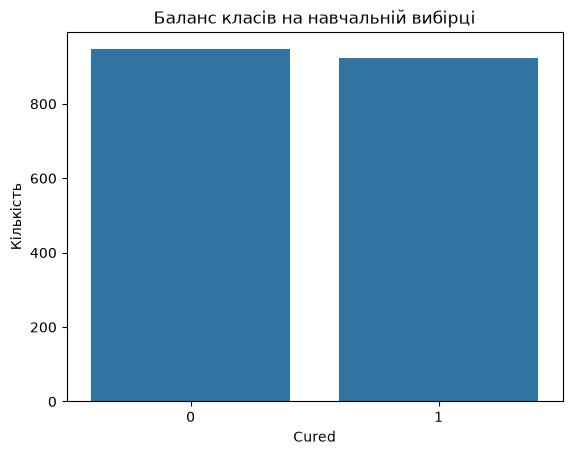

In [9]:
sns.countplot(x=y_train)
plt.title('Баланс класів на навчальній вибірці')
plt.ylabel('Кількість')
plt.show()

**Висновок:**
У навчальній вибірці 946 прикладів класу 0 і 924 приклади класу 1. Класи майже збалансовані. За сильного дисбалансу Accuracy могла б бути високою навіть для моделі, яка переважно прогнозує більший клас.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

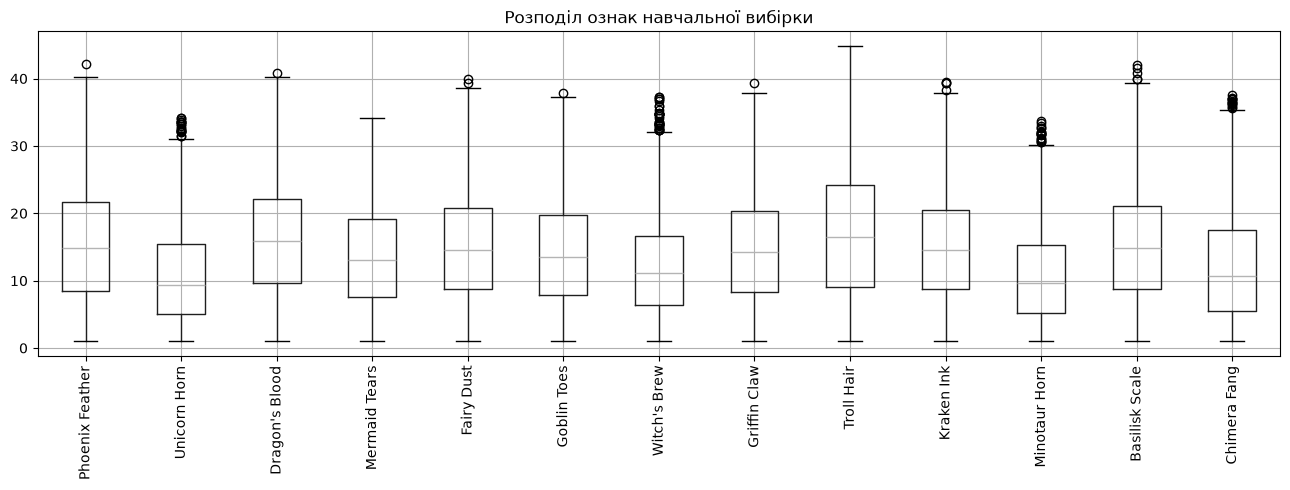

In [10]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Розподіл ознак навчальної вибірки')
plt.tight_layout()
plt.show()

In [11]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum()
outliers.sort_values(ascending=False)

Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64

**Висновок про викиди:**
Найбільше потенційних викидів у Witch's Brew — 33, Unicorn Horn — 20 і Minotaur Horn — 18. Правило 1,5 IQR знаходить незвичайні значення, але вони не обов'язково є помилками. Тому рядки не видаляємо.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

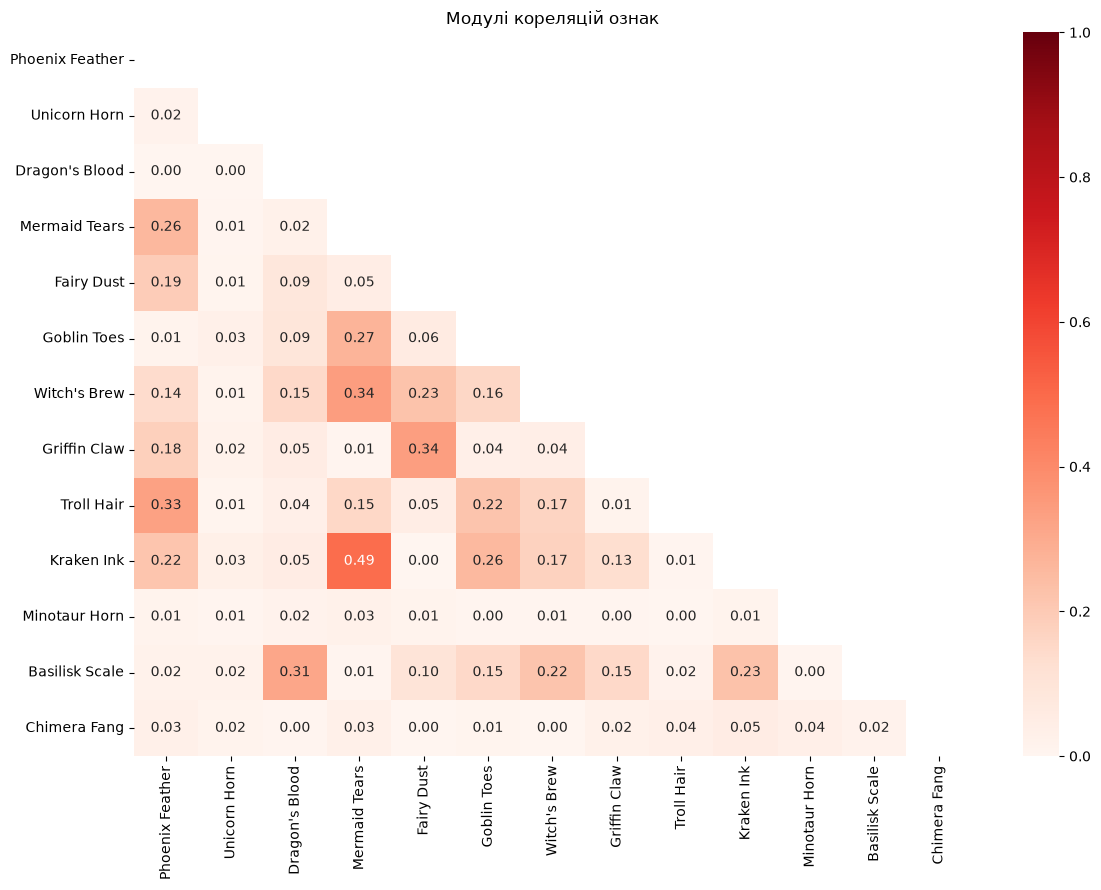

In [12]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Модулі кореляцій ознак')
plt.tight_layout()
plt.show()

In [13]:
target_corr = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured')
target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale    -0.042277
Kraken Ink        -0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw      -0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64

**Висновок про кореляції:**
Найбільші модулі кореляції між ознаками: Kraken Ink і Mermaid Tears — 0,491; Witch's Brew і Mermaid Tears — 0,343; Griffin Claw і Fairy Dust — 0,339. Дуже сильних лінійних зв'язків між ознаками немає. Найсильніший зв'язок із Cured мають Troll Hair (0,489) і Witch's Brew (0,247).

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Середні значення після стандартизації:', X_train_scaled.mean(axis=0).round(2))

Середні значення після стандартизації: [ 0.  0.  0. -0. -0.  0.  0. -0.  0.  0.  0.  0. -0.]


**Коментар:** середні значення стандартизованих навчальних ознак близькі до нуля. Тестові дані перетворено тим самим scaler без повторного навчання.

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
base_accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', base_accuracy)
print(classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

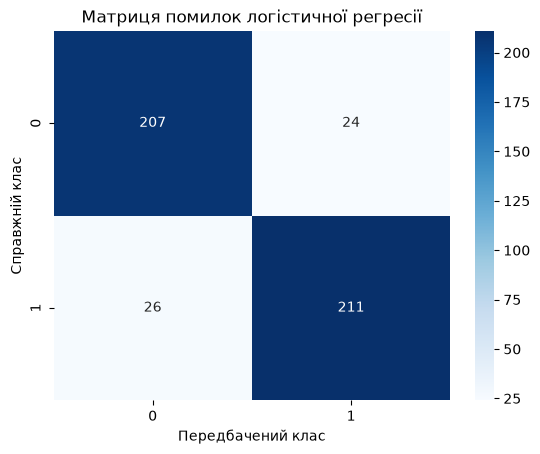

In [16]:
conf = confusion_matrix(y_test, y_pred)
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок логістичної регресії')
plt.show()

In [17]:
predictions = pd.DataFrame({'Справжній клас': y_test, 'Прогноз': y_pred})
predictions.sample(10, random_state=42)

,Справжній клас,Прогноз
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**
Accuracy становить 0,8932 (89,32%). Правильно класифіковано 418 із 468 прикладів. Хибнонегативних прогнозів трохи більше: 26 випадків класу 1 передбачено як 0, а 24 випадки класу 0 — як 1. Однієї Accuracy недостатньо: precision, recall, F1-score та матриця помилок показують якість для окремих класів. F1-score для класу 1 становить приблизно 0,8941.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
param_grid = {
    'C': [0.1, 1, 10],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 300]
}
param_dist = param_grid.copy()

In [19]:
grid = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring='accuracy')
grid.fit(X_train_scaled, y_train)
print('GridSearchCV:', grid.best_params_)
print('Найкраща CV Accuracy:', grid.best_score_)

GridSearchCV: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща CV Accuracy: 0.8673927508197171


In [20]:
random_search = RandomizedSearchCV(
    LogisticRegression(), param_dist, n_iter=6,
    cv=3, scoring='accuracy', random_state=42
)
random_search.fit(X_train_scaled, y_train)
print('RandomizedSearchCV:', random_search.best_params_)
print('Найкраща CV Accuracy:', random_search.best_score_)

RandomizedSearchCV: {'solver': 'lbfgs', 'max_iter': 300, 'C': 10}
Найкраща CV Accuracy: 0.8673927508197171


In [21]:
best_search = grid if grid.best_score_ >= random_search.best_score_ else random_search
best_model = best_search.best_estimator_
best_pred = best_model.predict(X_test_scaled)
tuned_accuracy = accuracy_score(y_test, best_pred)
print('Accuracy:', tuned_accuracy)
print(classification_report(y_test, best_pred))

Accuracy: 0.8931623931623932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**
GridSearchCV обрав C=10, solver='lbfgs', max_iter=100. RandomizedSearchCV обрав C=10, solver='lbfgs', max_iter=300. Обидва методи дали однакову середню CV Accuracy — 0,8674. Для подальшої перевірки взято модель GridSearchCV. На тестовій вибірці Accuracy залишилась 0,8932, а F1-score — 0,8941: покращення порівняно з базовою моделлю немає.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
svm = SVC()
tree = DecisionTreeClassifier(random_state=42)
svm.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)
tree_pred = tree.predict(X_test_scaled)

results = pd.DataFrame({
    'Модель': ['Логістична регресія (після підбору)', 'SVM', 'Дерево рішень'],
    'Accuracy': [accuracy_score(y_test, p) for p in [best_pred, svm_pred, tree_pred]],
    'F1-score': [f1_score(y_test, p) for p in [best_pred, svm_pred, tree_pred]]
})
display(results)
winner = results.sort_values(['Accuracy', 'F1-score'], ascending=False).iloc[0]
print('Найкраща модель за Accuracy (при рівності — за F1):', winner['Модель'])

,Модель,Accuracy,F1-score
0,Логістична регресія (після підбору),0.893162,0.894068
1,SVM,0.959402,0.960000
2,Дерево рішень,0.865385,0.865672


Найкраща модель за Accuracy (при рівності — за F1): SVM


**Коментар:** SVM має найвищі Accuracy (0,9594) та F1-score (0,9600), тому є найкращою серед трьох перевірених моделей на цій тестовій вибірці.

### 13. Висновки до лабораторної роботи

1. Датасет містить 2338 спостережень, 13 числових ознак і ціль Cured. Пропусків і дублікатів немає, класи майже збалансовані.
2. На навчальній вибірці найбільше потенційних викидів виявлено у Witch's Brew (33). Їх залишено, бо незвичайні значення можуть бути правильними. Найбільш корельована пара — Kraken Ink і Mermaid Tears (|r|=0,491); найсильніший зв'язок із Cured має Troll Hair (r=0,489).
3. Базова логістична регресія досягла Accuracy=0,8932 і F1-score=0,8941 на тестовій вибірці.
4. Підбір параметрів обрав C=10, але тестові Accuracy та F1-score не покращилися.
5. Найкращою на цій тестовій вибірці стала SVM: Accuracy=0,9594, F1-score=0,9600. Обидві метрики вищі, ніж у логістичної регресії (0,8932; 0,8941) та дерева рішень (0,8654; 0,8657), тому обираємо SVM.